# Topic modelling on reasoning traces — base version

**Goal.** Group sentences from model reasoning traces into a few topics, then look at what those topics contain.

This is a first, deliberately simple pipeline over all five runs (gpt-oss low/medium/high,
DeepSeek high/max). The fuller analysis lives in `trace_topics.ipynb`
(prompt-copy filtering, 40 topics, reasoning-move codebook, flip analysis).

**Pipeline (what we do)**

1. Load page-level traces (already prepared in `analysis/derived/page_outcomes.parquet`).
2. Split each reasoning text into sentences.
3. Embed unique sentences with a small local model (`all-MiniLM-L6-v2`).
4. Fit a small **BERTopic** model (UMAP → k-means, fixed number of topics).
5. Inspect each topic via keywords + example sentences.
6. Compare how often topics appear across runs.

## 0. Setup

We only need paths, pandas/numpy/matplotlib, and later the embedding + clustering libraries.
`page_outcomes.parquet` already joins traces with page outcomes from `run_comparison.ipynb`.

In [11]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent

DERIVED = ROOT / "analysis" / "derived"
SEED = 42
N_TOPICS = 10  # keep small for a first look
EMBED_MODEL = "all-MiniLM-L6-v2"

# All runs with page-level reasoning in page_outcomes.parquet.
KEEP_RUNS = [
    "gpt-oss low", "gpt-oss medium", "gpt-oss high",
    "DeepSeek high", "DeepSeek max",
]

## 1. Load traces

Each row is one page call: report, page, run, the full `reasoning` string, and an outcome category.
We keep only rows where a reasoning trace is actually present.

In [12]:
pages = pd.read_parquet(DERIVED / "page_outcomes.parquet")
pages = pages[pages.trace_state == "present"].copy()
pages = pages[pages.run.isin(KEEP_RUNS)].reset_index(drop=True)
pages["trace_id"] = np.arange(len(pages))

print(f"{len(pages):,} traces")
display(pages.groupby("run", observed=True).size().rename("traces").to_frame())
display(pages[["run", "report", "page", "category", "reasoning"]].head(2))

3,826 traces


,traces
run,
DeepSeek high,959
DeepSeek max,466
gpt-oss high,469
gpt-oss low,966
gpt-oss medium,966


,run,report,page,category,reasoning
0,gpt-oss low,balanced commercial property trust_2020_report.pdf,15,"correct, no gold values",We need extract values but none present for emissions. No CO2 numbers. So output empty list.
1,gpt-oss low,balanced commercial property trust_2020_report.pdf,16,"correct, no gold values","We need extract Scope1, Scope2 location-based (since not specified), Scope3 total if present. From excerpt only total carbon emissions k..."


## 2. Split reasoning into sentences

Topic models work better on short units. Whole traces mostly differ by *page content*;
sentences are closer to individual reasoning steps.

We split on line breaks and on `.?!` followed by a capital letter / quote, and drop tiny fragments.

In [13]:
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def sentences(text: str) -> list[str]:
    out = []
    for part in SPLIT.split(text or ""):
        part = re.sub(r"\s+", " ", part).strip(" -*•\t")
        if len(part.split()) >= 3:
            out.append(part)
    return out


seg = pd.DataFrame(
    [
        (row.trace_id, row.run, i, text)
        for row in pages.itertuples()
        for i, text in enumerate(sentences(row.reasoning))
    ],
    columns=["trace_id", "run", "pos", "text"],
)

print(f"{len(seg):,} sentences  |  {seg.text.nunique():,} unique")
display(
    pd.DataFrame({
        "sentences": seg.groupby("run", observed=True).size(),
        "median per trace": seg.groupby(["run", "trace_id"], observed=True).size()
            .groupby("run", observed=True).median(),
    })
)
display(seg.head(5))

132,020 sentences  |  82,908 unique


,sentences,median per trace
run,,
DeepSeek high,44383,11.0
DeepSeek max,32494,14.0
gpt-oss high,38785,41.0
gpt-oss low,3711,2.0
gpt-oss medium,12647,9.0


,trace_id,run,pos,text
0,0,gpt-oss low,0,We need extract values but none present for emissions.
1,0,gpt-oss low,1,No CO2 numbers.
2,0,gpt-oss low,2,So output empty list.
3,1,gpt-oss low,0,"We need extract Scope1, Scope2 location-based (since not specified), Scope3 total if present."
4,1,gpt-oss low,1,"From excerpt only total carbon emissions kg CO2e 1,780,437 (2020) and 2,133,908 (2019)."


## 3. Embed sentences

We convert each *unique* sentence into a vector with `SentenceTransformer`.
Similar meaning → similar vectors. That is the input for clustering.

No API calls: the model runs locally.

In [14]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
uniq = seg.text.drop_duplicates().tolist()
E = embedder.encode(uniq, batch_size=256, normalize_embeddings=True, show_progress_bar=True)

sent = pd.DataFrame({"text": uniq})
print(f"embedding matrix: {E.shape[0]:,} sentences × {E.shape[1]} dims")

Batches: 100%|██████████| 324/324 [01:59<00:00,  2.72it/s]

embedding matrix: 82,908 sentences × 384 dims


## 4. Topic model with BERTopic

**Idea.** Put similar sentence vectors into the same group, then label each group with keywords.

We use BERTopic with:
- the MiniLM embeddings from above
- UMAP to reduce dimensionality
- **k-means** (instead of HDBSCAN) with fixed `N_TOPICS`, so every sentence gets a topic
- KeyBERT-style keywords for readable topic labels

This is the same core as `trace_topics.ipynb`, just with fewer topics and no prompt-copy filter yet.

In [15]:
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

docs = sent["text"].tolist()

topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=UMAP(
        n_neighbors=15, n_components=5, min_dist=0.0,
        metric="cosine", random_state=SEED,
    ),
    # BERTopic expects this argument name even when we pass k-means.
    hdbscan_model=KMeans(n_clusters=N_TOPICS, random_state=SEED, n_init=10),
    vectorizer_model=CountVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=5,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
    ),
    representation_model=KeyBERTInspired(),
    calculate_probabilities=False,
)

topics, _ = topic_model.fit_transform(docs, E)
sent["topic"] = topics

info = topic_model.get_topic_info()
topic_info = pd.DataFrame({
    "topic": info.Topic,
    "n": info.Count,
    "keywords": info.Representation.map(lambda w: ", ".join(w[:8])),
})
display(topic_info)

# Attach topic labels back to every sentence occurrence in the traces.
seg = seg.drop(columns=[c for c in ["topic"] if c in seg.columns], errors="ignore")
seg = seg.merge(sent[["text", "topic"]], on="text", how="left")
print(f"{seg.topic.nunique()} topics on {len(seg):,} sentence occurrences")

,topic,n,keywords
0,0,22548,"total emissions, emissions total, emissions values, ghg emissions, emissions, gas emissions, scope emissions, direct emissions"
1,1,12357,"scope, values refer, values, extract values, extract, says extract, assets, data"
2,2,12152,"values, value, total, chart, numeric, number, numbers, metric names"
3,3,11814,"scope total, scope values, total scope, scope value, values, values scope, values available, sum scopes"
4,4,6267,"total values, values present, values, values need, entries, values output, value, values extract"
5,5,5998,"total total, year report, values year, report year, year range, year values, total, entries year"
6,6,5632,"null, null available, values, value, scope emissions, emissions, extract report, excerpt"
7,7,3645,"extract values, need extract, extract, says extract, extract absolute, extraction, values, total values"
8,8,1777,"include, requires, let produce, according, exactly, minimum, correct, following"
9,9,718,"extracted, output, need output, unit output, unit null, null, null unit, null need"


10 topics on 132,020 sentence occurrences


## 5. What do these topics mean?

BERTopic does **not** know what “reasoning” is. It only groups sentences that are
*lexically / semantically similar*. So a topic is just a cluster of similar sentences.

**How to read a topic**
1. Look at the **keywords** — frequent distinctive words in that cluster.
2. Read the **example sentences** — they matter more than the keywords.
3. Give the cluster a short **human label** in your own words.

Typical labels in this project look like: *task interpretation*, *reading the excerpt*,
*applying a rule*, *computing / converting a value*, *hesitation / revision*,
*producing the JSON answer*. Some clusters will be messy mixtures — that is normal
with only 10 topics.

Fill in `TOPIC_LABELS` below after you read the examples. Until then, plots use topic IDs.

In [16]:
def show_topics(n_examples: int = 5) -> pd.DataFrame:
    kw = topic_info.set_index("topic")["keywords"]
    rows = []
    for topic, g in seg.groupby("topic"):
        examples = (
            g.drop_duplicates("text")
             .sample(min(n_examples, g.text.nunique()), random_state=SEED)
             .text.tolist()
        )
        rows.append({
            "topic": int(topic),
            "n": len(g),
            "n_unique": g.text.nunique(),
            "keywords": kw.get(topic, ""),
            "examples": examples,
        })
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)


topic_table = show_topics()

# Print one topic at a time — easier to interpret than a wide table.
for row in topic_table.itertuples():
    print("=" * 88)
    print(f"Topic {row.topic}  |  {row.n:,} sentences ({row.n_unique:,} unique)")
    print(f"keywords: {row.keywords}")
    for i, ex in enumerate(row.examples, 1):
        print(f"  {i}. {ex}")

# Optional: after reading the examples, replace None with your labels.
# Example: 3: "reading the table / excerpt"
TOPIC_LABELS = {int(t): None for t in topic_table.topic}

# Uncomment / edit once you have labels, e.g.:
# TOPIC_LABELS = {
#     0: "task / instruction restatement",
#     1: "reading numbers from the excerpt",
#     2: "applying extraction rules",
#     ...
# }

labeled = {t: (TOPIC_LABELS[t] or f"topic {t}") for t in TOPIC_LABELS}
seg["topic_label"] = seg["topic"].map(labeled)
display(pd.DataFrame({
    "topic": list(labeled),
    "label": [labeled[t] for t in labeled],
    "keywords": topic_table.set_index("topic").reindex(labeled).keywords,
}))

Topic 0  |  31,134 sentences (22,548 unique)
keywords: total emissions, emissions total, emissions values, ghg emissions, emissions, gas emissions, scope emissions, direct emissions
  1. This table likely contains target/result values for CO2 per unit, not absolute.
  2. Line 11: "Scope 1 Scope 2 Scope 3 Total emissions"
  3. Total emissions 28,711 is absolute but it's total emissions across scopes?
  4. It mentions "we have reduced the GHG emissions by 8,500 metric tons of CO2 eqv. compared to 2017".
  5. Let's examine the exact text: "GHG-Indir-Abs 2019 2020 GHG-Dir-Abs 86 83 0 300 ... 772,607 694,329 1,361,302 1,086,109".
Topic 2  |  18,342 sentences (12,152 unique)
keywords: values, value, total, chart, numeric, number, numbers, metric names
  1. Let's look at the encoded "compared with " for "219,162": =2, =1, =6?
  2. The text "2,2 1,71,9 1,6" - if original had "2.2 1.7 1.9 1.6", OCR might have read "." as ",".
  3. There is mention of "100 80 60 40 20 0 120 ..." but th

,topic,label,keywords
topic,,,
0,0,topic 0,"total emissions, emissions total, emissions values, ghg emissions, emissions, gas emissions, scope emissions, direct emissions"
2,2,topic 2,"values, value, total, chart, numeric, number, numbers, metric names"
4,4,topic 4,"total values, values present, values, values need, entries, values output, value, values extract"
1,1,topic 1,"scope, values refer, values, extract values, extract, says extract, assets, data"
3,3,topic 3,"scope total, scope values, total scope, scope value, values, values scope, values available, sum scopes"
5,5,topic 5,"total total, year report, values year, report year, year range, year values, total, entries year"
8,8,topic 8,"include, requires, let produce, according, exactly, minimum, correct, following"
7,7,topic 7,"extract values, need extract, extract, says extract, extract absolute, extraction, values, total values"
6,6,topic 6,"null, null available, values, value, scope emissions, emissions, extract report, excerpt"


## 6. Compare runs

Share of sentences per topic, by run (gpt-oss and DeepSeek).
If more reasoning effort changes *what* the model writes (not only *how much*),
the topic mix should shift — not only the total number of sentences.

Bars use your `TOPIC_LABELS` when filled in; otherwise topic IDs.

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
topic_label,,,,,
topic 0,21.1%,22.4%,27.2%,22.6%,21.3%
topic 2,15.7%,11.3%,11.4%,16.6%,14.0%
topic 4,33.5%,17.1%,13.6%,10.8%,11.8%
topic 1,3.1%,6.4%,13.4%,11.2%,12.4%
topic 3,14.1%,10.6%,5.7%,13.3%,14.3%
topic 5,5.7%,6.3%,12.6%,6.6%,6.4%
topic 8,0.3%,9.9%,5.4%,7.1%,6.4%
topic 7,1.8%,10.5%,7.1%,5.7%,5.7%
topic 6,4.6%,5.0%,2.5%,5.5%,7.3%


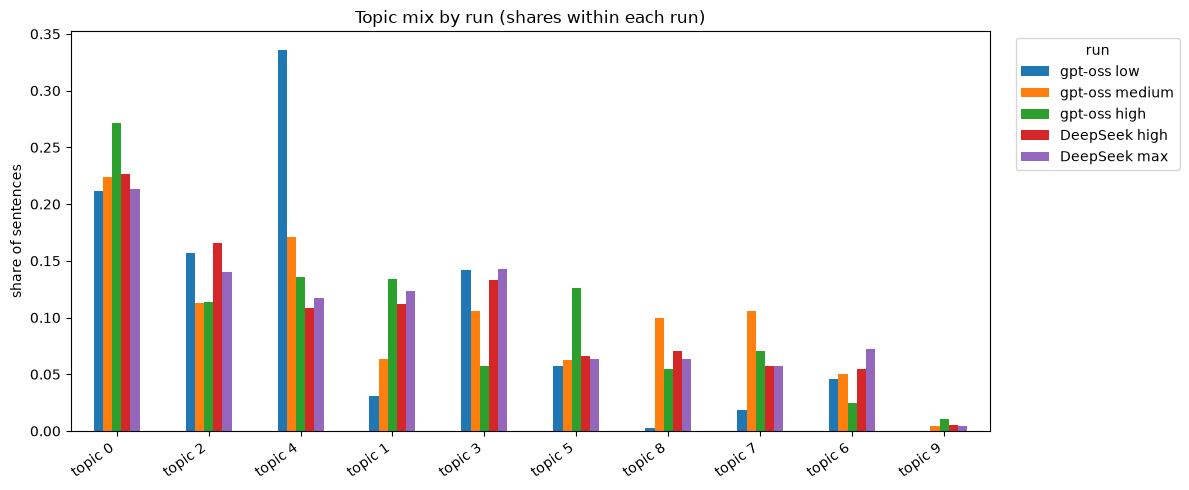

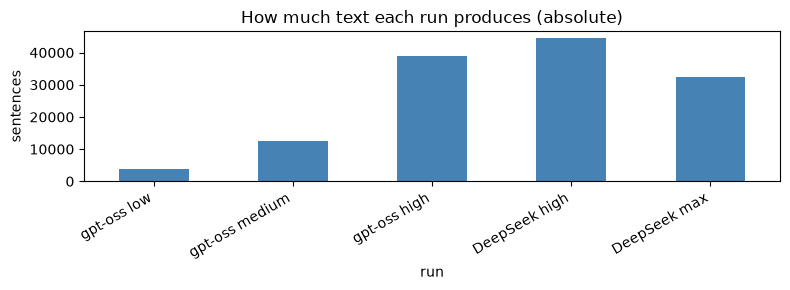

In [17]:
share = (
    seg.groupby(["run", "topic_label"], observed=True).size()
       .groupby("run", observed=True).transform(lambda s: s / s.sum())
       .rename("share")
       .reset_index()
)
# Keep topic order by size overall.
label_order = (
    seg.groupby("topic_label").size().sort_values(ascending=False).index.tolist()
)
pivot = (
    share.pivot(index="topic_label", columns="run", values="share")
         .fillna(0)
         .reindex(label_order)
         .reindex(columns=KEEP_RUNS)
)
display(pivot.style.format("{:.1%}"))

ax = pivot.plot(kind="bar", figsize=(12, 5))
ax.set_ylabel("share of sentences")
ax.set_xlabel("")
ax.set_title("Topic mix by run (shares within each run)")
ax.legend(title="run", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Sentence volume still differs a lot by run — show that separately.
vol = seg.groupby("run", observed=True).size().reindex(KEEP_RUNS)
ax = vol.plot(kind="bar", figsize=(8, 3), color="steelblue")
ax.set_ylabel("sentences")
ax.set_title("How much text each run produces (absolute)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()